# CUDA Numeric & Machine Learning Library vs NumPy, SciPy & Scikit-Learn
### End-to-End Performance Benchmark Suite & Visual Ray Tracer

This notebook comprehensively benchmarks our custom **native CUDA numerical library (`numeric_cuda.py` & `raytracer_cuda`)** against standard CPU libraries:
* **NumPy** (BLAS/LAPACK & vectorized C operations)
* **SciPy** (Spatial distance metrics, 2D stencils, special functions)
* **Scikit-Learn** (Estimators: K-Means, PCA, Logistic Regression, Linear Regression, KNN, Gaussian Naive Bayes)

#### Benchmark Structure:
1. **Dataset 1: HIGGS** (Tabular Classification, Clustering, PCA, Reductions & Activations)
2. **Dataset 2: YearPredictionMSD** (Continuous Regression, KNN Regressor, MSE Loss)
3. **Dataset 3: SIFT / High-Dimensional Vectors** (Pairwise Euclidean, Cosine, Manhattan distances & KNN Classifier)
4. **Dataset 4: High-Resolution Raster / Imagery** (2D Image Correlation Stencil & Elementwise Thresholding)
5. **Dataset 5: HPC Primitives** (Dense GEMM Matrix Multiply, Thrust Radix Sort, Parallel Prefix Scan)
6. **Comparative Visual Performance Graphs** (Grouped execution time bars and speedup multiplier factor charts)
7. **Ray Tracer Comparative Visualizations** (Side-by-side rendering comparing Python CPU vs CUDA ray tracing)

In [1]:
# =====================================================================
# 1. Environment Setup & Library Imports
# =====================================================================
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# CPU Reference Libraries
import scipy
import scipy.spatial.distance as sp_dist
import scipy.signal as sp_signal
import scipy.special as sp_special
import sklearn
from sklearn.linear_model import LogisticRegression as SkLogisticRegression, LinearRegression as SkLinearRegression
from sklearn.cluster import KMeans as SkKMeans
from sklearn.decomposition import PCA as SkPCA
from sklearn.naive_bayes import GaussianNB as SkGaussianNB
from sklearn.neighbors import KNeighborsClassifier as SkKNNClassifier, KNeighborsRegressor as SkKNNRegressor
from sklearn.metrics import mean_squared_error as sk_mse, log_loss as sk_log_loss

# Our Custom CUDA Numerical Library & C-Extension
import numeric_cuda as nc
import raytracer_cuda

print("=" * 70)
print("  BENCHMARK ENVIRONMENT INITIALIZED")
print("=" * 70)
print(f"  Python Version:       {sys.version.split()[0]}")
print(f"  NumPy Version:        {np.__version__}")
print(f"  SciPy Version:        {scipy.__version__}")
print(f"  Scikit-Learn Version: {sklearn.__version__}")
print(f"  CUDA Extension:       Loaded successfully ({raytracer_cuda.__file__})")
print("=" * 70)
# ---- Pre-flight: make sure every nc.* function this notebook uses really exists ----
_required = [
    "LogisticRegression", "GaussianNB", "KMeans", "PCA", "LinearRegression",
    "KNeighborsRegressor", "KNeighborsClassifier",
    "var", "binary_cross_entropy", "gelu", "mse_loss", "cdist",
    "correlate2d_5x5", "clip", "where", "matmul", "sort", "cumsum", "argmax",
]
_missing = [n for n in _required if not hasattr(nc, n)]
assert not _missing, f"numeric_cuda is missing: {_missing}"
print("  numeric_cuda API check: all required functions present")


  BENCHMARK ENVIRONMENT INITIALIZED
  Python Version:       3.13.5
  NumPy Version:        2.4.6
  SciPy Version:        1.18.1
  Scikit-Learn Version: 1.9.1
  CUDA Extension:       Loaded successfully (c:\Engineering\FInal-Porj\raytracer_cuda.cp313-win_amd64.pyd)
  numeric_cuda API check: all required functions present


In [2]:
# =====================================================================
# 2. Benchmark Measurement Engine
# =====================================================================
benchmark_results = []

def run_benchmark(name, category, cuda_fn, cpu_fn, warmup=True, n_runs=1, check=None):
    """
    Times a CUDA function and its CPU reference, records the speedup, and
    optionally verifies the two results agree.

    check : optional callable (cuda_res, cpu_res) -> str describing agreement
            (e.g. max relative error). A wrong-but-fast GPU result is useless.

    Unlike the original version, a failing CUDA call is NOT silently swallowed:
    the error is printed and the benchmark is recorded as failed (NaN) instead
    of crashing the whole notebook or reporting a meaningless time.
    """
    # 1. Warm-up (CUDA context init / JIT / allocator) - errors are reported, not hidden
    if warmup:
        try:
            cuda_fn()
        except Exception as e:
            print(f"[{category}] {name:<36} | CUDA FAILED: {type(e).__name__}: {e}")
            benchmark_results.append({"Benchmark": name, "Category": category,
                                      "CUDA Time (s)": np.nan, "CPU Time (s)": np.nan,
                                      "Speedup": np.nan})
            return None, None

    # 2. CUDA timing (includes host<->device transfers, since the bindings copy NumPy arrays)
    t0 = time.perf_counter()
    for _ in range(n_runs):
        cuda_res = cuda_fn()
    t_cuda = (time.perf_counter() - t0) / n_runs

    # 3. CPU reference timing
    t0 = time.perf_counter()
    for _ in range(n_runs):
        cpu_res = cpu_fn()
    t_cpu = (time.perf_counter() - t0) / n_runs

    speedup = (t_cpu / t_cuda) if t_cuda > 0 else np.nan
    benchmark_results.append({"Benchmark": name, "Category": category,
                              "CUDA Time (s)": t_cuda, "CPU Time (s)": t_cpu,
                              "Speedup": speedup})
    msg = (f"[{category}] {name:<36} | CUDA: {t_cuda*1000:9.2f} ms | "
           f"CPU: {t_cpu*1000:9.2f} ms | Speedup: {speedup:6.2f}x")
    if check is not None:
        try:
            msg += f" | check: {check(cuda_res, cpu_res)}"
        except Exception as e:
            msg += f" | check failed: {e}"
    print(msg)
    return cuda_res, cpu_res


def rel_err(a, b):
    """Max relative error between two array-likes (scalar-safe)."""
    a = np.asarray(a, dtype=np.float64); b = np.asarray(b, dtype=np.float64)
    return float(np.max(np.abs(a - b) / (np.abs(b) + 1e-12)))

# --- Thin shape-safe wrappers --------------------------------------------------
# The CUDA bindings for clip / where only accept contiguous 1-D float32 arrays
# (and where() needs all three arguments as arrays). These helpers flatten N-D
# inputs, broadcast scalars, call the CUDA kernel and restore the original shape.
def cuda_clip_nd(x, lo, hi):
    x = np.ascontiguousarray(x, dtype=np.float32)
    return nc.clip(x.reshape(-1), lo, hi).reshape(x.shape)

def cuda_where_nd(cond, a, b):
    cond = np.ascontiguousarray(cond, dtype=bool)
    a = np.broadcast_to(np.asarray(a, dtype=np.float32), cond.shape)
    b = np.broadcast_to(np.asarray(b, dtype=np.float32), cond.shape)
    out = nc.where(cond.reshape(-1),
                   np.ascontiguousarray(a).reshape(-1),
                   np.ascontiguousarray(b).reshape(-1))
    return out.reshape(cond.shape)

print("Benchmark runner helper defined.")


Benchmark runner helper defined.


--- 
## Dataset 1: HIGGS Benchmark
**Workload:** Dense tabular data (28 features, binary classification label).
* **Location:** `datasets/HIGGS.csv` (or `datasets/HIGGS.csv.gz`)
* If not yet downloaded, an automatic high-volume synthetic fallback of 500,000 samples $\times$ 28 features is generated.

In [3]:
# Load or Generate HIGGS Dataset
higgs_path = os.path.join("datasets", "HIGGS.csv")
higgs_gz_path = os.path.join("datasets", "HIGGS.csv.gz")

if os.path.exists(higgs_path) or os.path.exists(higgs_gz_path):
    target_file = higgs_path if os.path.exists(higgs_path) else higgs_gz_path
    print(f"Loading HIGGS dataset from {target_file}...")
    # Read up to 1,000,000 rows for memory safety on local machines
    df_higgs = pd.read_csv(target_file, nrows=1000000, header=None, dtype=np.float32)
    y_higgs = df_higgs.iloc[:, 0].to_numpy(dtype=np.float32)
    X_higgs = df_higgs.iloc[:, 1:].to_numpy(dtype=np.float32)
    print(f"Loaded HIGGS: X shape = {X_higgs.shape}, y shape = {y_higgs.shape}")
else:
    print("[INFO] 'datasets/HIGGS.csv' not found yet in 'datasets/'.")
    print("Generating equivalent 500,000 x 28 synthetic HIGGS float32 dataset for immediate benchmark...")
    np.random.seed(42)
    n_samples, n_features = 500000, 28
    X_higgs = np.random.randn(n_samples, n_features).astype(np.float32)
    y_higgs = (X_higgs[:, 0] * 0.8 + X_higgs[:, 1] * 0.5 + np.random.randn(n_samples) > 0).astype(np.float32)
    print(f"Synthetic HIGGS ready: X shape = {X_higgs.shape}, y shape = {y_higgs.shape}")

Loading HIGGS dataset from datasets\HIGGS.csv.gz...
Loaded HIGGS: X shape = (1000000, 28), y shape = (1000000,)


In [4]:
# -----------------------------------------------------------------
# Benchmarking Estimators & Math Functions on HIGGS
# -----------------------------------------------------------------
print("Running HIGGS Benchmarks...")

# 1. Logistic Regression (GPU gradient descent vs sklearn SAG - different solvers, compare accuracy)
run_benchmark(
    "Logistic Regression (100 iters)", "HIGGS / ML",
    cuda_fn=lambda: nc.LogisticRegression(lr=0.01, max_iter=100).fit(X_higgs, y_higgs),
    cpu_fn=lambda: SkLogisticRegression(max_iter=100, solver='sag', random_state=42).fit(X_higgs, y_higgs),
    check=lambda g, c: f"acc CUDA={np.mean(g.predict(X_higgs[:50000]) == y_higgs[:50000]):.3f} "
                       f"CPU={c.score(X_higgs[:50000], y_higgs[:50000]):.3f}"
)

# 2. Gaussian Naive Bayes (class stats & log-likelihood prediction)
X_test_nb = X_higgs[:20000]
run_benchmark(
    "Gaussian Naive Bayes (Fit+Pred)", "HIGGS / ML",
    cuda_fn=lambda: nc.GaussianNB().fit(X_higgs, y_higgs).predict(X_test_nb),
    cpu_fn=lambda: SkGaussianNB().fit(X_higgs, y_higgs).predict(X_test_nb),
    check=lambda g, c: f"label agreement={np.mean(g == c):.4f}"
)

# 3. K-Means Clustering (k=8, 20 iterations)
X_sub_km = X_higgs[:100000]
run_benchmark(
    "K-Means Clustering (100k pts, k=8)", "HIGGS / ML",
    cuda_fn=lambda: nc.KMeans(n_clusters=8, max_iter=20, random_state=42).fit(X_sub_km),
    cpu_fn=lambda: SkKMeans(n_clusters=8, max_iter=20, n_init=1, random_state=42).fit(X_sub_km),
    check=lambda g, c: f"inertia CUDA={g.inertia_:.4g} CPU={c.inertia_:.4g}"
)

# 4. Principal Component Analysis (5 components)
X_sub_pca = X_higgs[:100000]
run_benchmark(
    "PCA Transform (5 components)", "HIGGS / ML",
    cuda_fn=lambda: nc.PCA(n_components=5, max_iter=20).fit_transform(X_sub_pca),
    cpu_fn=lambda: SkPCA(n_components=5).fit_transform(X_sub_pca),
    check=lambda g, c: f"output shapes CUDA={g.shape} CPU={c.shape}"
)

# 5. Variance reduction.
# FIX: nc.var() flattens its input and returns ONE scalar, while np.var(X, axis=0)
# returns 28 per-feature variances - the two were not computing the same thing.
# Compare like with like: global variance over all elements.
run_benchmark(
    "Variance Reduction (all elements)", "HIGGS / Reductions",
    cuda_fn=lambda: nc.var(X_higgs),
    cpu_fn=lambda: np.var(X_higgs),
    check=lambda g, c: f"rel.err={rel_err(g, c):.2e}"
)

# 6. Binary Cross Entropy Loss
y_prob_sample = (1.0 / (1.0 + np.exp(-X_higgs[:, 0]))).astype(np.float32)
run_benchmark(
    "Binary Cross-Entropy Loss", "HIGGS / Losses",
    cuda_fn=lambda: nc.binary_cross_entropy(y_prob_sample, y_higgs),
    cpu_fn=lambda: sk_log_loss(y_higgs, y_prob_sample),
    check=lambda g, c: f"rel.err={rel_err(g, c):.2e}"
)

# 7. Elementwise GELU Activation (tanh approximation - same formula as the CUDA kernel)
x_flat = X_higgs.ravel()
run_benchmark(
    "GELU Activation (Elementwise)", "HIGGS / Math",
    cuda_fn=lambda: nc.gelu(x_flat),
    cpu_fn=lambda: 0.5 * x_flat * (1.0 + np.tanh(np.sqrt(2.0 / np.pi) * (x_flat + 0.044715 * x_flat**3))),
    check=lambda g, c: f"max abs err={np.max(np.abs(g - c)):.2e}"
)


Running HIGGS Benchmarks...
[HIGGS / ML] Logistic Regression (100 iters)      | CUDA:  38942.43 ms | CPU:  16888.08 ms | Speedup:   0.43x | check: acc CUDA=0.533 CPU=0.640
[HIGGS / ML] Gaussian Naive Bayes (Fit+Pred)      | CUDA:    376.68 ms | CPU:    523.05 ms | Speedup:   1.39x | check: label agreement=1.0000
[HIGGS / ML] K-Means Clustering (100k pts, k=8)   | CUDA:   1036.64 ms | CPU:    352.53 ms | Speedup:   0.34x | check: inertia CUDA=1.443e+06 CPU=1.445e+06
[HIGGS / ML] PCA Transform (5 components)         | CUDA:    759.17 ms | CPU:     19.07 ms | Speedup:   0.03x | check: output shapes CUDA=(100000, 5) CPU=(100000, 5)
[HIGGS / Reductions] Variance Reduction (all elements)    | CUDA:    320.02 ms | CPU:    120.64 ms | Speedup:   0.38x | check: rel.err=7.26e-08
[HIGGS / Losses] Binary Cross-Entropy Loss            | CUDA:     38.80 ms | CPU:    193.97 ms | Speedup:   5.00x | check: rel.err=9.64e-09
[HIGGS / Math] GELU Activation (Elementwise)        | CUDA:    216.80 ms | CPU: 

(array([ 0.7019836 , -0.16686808,  0.13299367, ...,  0.16471344,
         0.55342543,  0.43638957], shape=(28000000,), dtype=float32),
 array([ 0.70198362, -0.16686808,  0.13299367, ...,  0.16471344,
         0.55342543,  0.43638955], shape=(28000000,)))

--- 
## Dataset 2: YearPredictionMSD (Million Song Dataset)
**Workload:** High-dimensional continuous regression (90 acoustic features, 515,345 records).
* **Location:** `datasets/YearPredictionMSD.txt`
* Evaluates Linear Regression, K-Neighbors Regressor, and Mean Squared Error reduction.

In [5]:
# Load or Generate YearPredictionMSD Dataset
msd_path = os.path.join("datasets", "YearPredictionMSD.txt")
if os.path.exists(msd_path):
    print(f"Loading YearPredictionMSD from {msd_path}...")
    df_msd = pd.read_csv(msd_path, header=None, nrows=200000, dtype=np.float32)
    y_msd = df_msd.iloc[:, 0].to_numpy(dtype=np.float32)
    X_msd = df_msd.iloc[:, 1:].to_numpy(dtype=np.float32)
else:
    print("[INFO] 'datasets/YearPredictionMSD.txt' not found yet in 'datasets/'.")
    print("Generating equivalent 200,000 x 90 synthetic continuous features...")
    np.random.seed(42)
    X_msd = np.random.randn(200000, 90).astype(np.float32)
    true_w = np.random.randn(90).astype(np.float32)
    y_msd = X_msd @ true_w + 1995.0 + np.random.randn(200000).astype(np.float32) * 5.0

print(f"MSD Ready: X shape = {X_msd.shape}, y shape = {y_msd.shape}")

Loading YearPredictionMSD from datasets\YearPredictionMSD.txt...
MSD Ready: X shape = (200000, 90), y shape = (200000,)


In [6]:
print("Running YearPredictionMSD Benchmarks...")

# 1. Linear Regression (GPU normal equations vs sklearn OLS)
run_benchmark(
    "Linear Regression Fit (200k x 90)", "MSD / Regression",
    cuda_fn=lambda: nc.LinearRegression().fit(X_msd, y_msd),
    cpu_fn=lambda: SkLinearRegression().fit(X_msd, y_msd),
    check=lambda g, c: f"max |coef diff|={np.max(np.abs(g.coef_ - c.coef_)):.2e}"
)

# 2. K-Neighbors Regressor (50k train points, 500 query points, k=5)
X_train_knn_r = X_msd[:50000]
y_train_knn_r = y_msd[:50000]
X_query_knn_r = X_msd[50000:50500]
run_benchmark(
    "KNN Regressor (50k train, 500 query)", "MSD / KNN",
    cuda_fn=lambda: nc.KNeighborsRegressor(n_neighbors=5).fit(X_train_knn_r, y_train_knn_r).predict(X_query_knn_r),
    cpu_fn=lambda: SkKNNRegressor(n_neighbors=5, algorithm='brute').fit(X_train_knn_r, y_train_knn_r).predict(X_query_knn_r),
    check=lambda g, c: f"max |pred diff|={np.max(np.abs(g - c)):.2e}"
)

# 3. Mean Squared Error
# FIX: nc.cuda_mse_loss_f32 does not exist in numeric_cuda.py - the public wrapper is nc.mse_loss.
y_pred_dummy = (y_msd + 2.5).astype(np.float32)
run_benchmark(
    "Mean Squared Error (200k items)", "MSD / Losses",
    cuda_fn=lambda: nc.mse_loss(y_pred_dummy, y_msd),
    cpu_fn=lambda: sk_mse(y_msd, y_pred_dummy),
    check=lambda g, c: f"rel.err={rel_err(g, c):.2e}"
)


Running YearPredictionMSD Benchmarks...
[MSD / Regression] Linear Regression Fit (200k x 90)    | CUDA:    565.15 ms | CPU:    816.37 ms | Speedup:   1.44x | check: max |coef diff|=2.52e+02
[MSD / KNN] KNN Regressor (50k train, 500 query) | CUDA:   2018.57 ms | CPU:    112.00 ms | Speedup:   0.06x | check: max |pred diff|=0.00e+00
[MSD / Losses] Mean Squared Error (200k items)      | CUDA:      4.30 ms | CPU:      1.77 ms | Speedup:   0.41x | check: rel.err=0.00e+00


(6.25, 6.25)

--- 
## Dataset 3: SIFT / High-Dimensional Vector Distance Metrics
**Workload:** 128-dimensional dense vectors (SIFT descriptor format).
* **Location:** `datasets/sift.npy` (or auto-generated $50,000 \times 128$ vectors with $1,000$ queries).
* Stresses 2D shared-memory tiled Euclidean, Cosine, and Manhattan distance kernels against `scipy.spatial.distance.cdist`.

In [7]:
# Load or Generate SIFT-128 Vectors
sift_path = os.path.join("datasets", "sift.npy")
if os.path.exists(sift_path):
    print(f"Loading SIFT from {sift_path}...")
    X_sift = np.load(sift_path).astype(np.float32)
else:
    print("[INFO] 'datasets/sift.npy' not found yet. Generating 50,000 x 128 SIFT vectors...")
    np.random.seed(42)
    X_sift = np.random.randn(50000, 128).astype(np.float32)

n_total = len(X_sift)
n_queries = min(1000, max(100, n_total // 10))
X_base_sift = X_sift[:-n_queries]
X_query_sift = X_sift[-n_queries:]
y_base_sift = np.random.randint(0, 10, size=len(X_base_sift))

print(f"SIFT Base: {X_base_sift.shape}, SIFT Queries: {X_query_sift.shape}")


Loading SIFT from datasets\sift.npy...
SIFT Base: (9000, 128), SIFT Queries: (1000, 128)


In [8]:
print("Running SIFT Distance Metric Benchmarks...")

# 1. Pairwise Euclidean Distance
run_benchmark(
    "cdist Euclidean (Queries x Base)", "SIFT / Distances",
    cuda_fn=lambda: nc.cdist(X_query_sift, X_base_sift, metric="euclidean"),
    cpu_fn=lambda: sp_dist.cdist(X_query_sift, X_base_sift, metric="euclidean"),
    check=lambda g, c: f"max abs err={np.max(np.abs(g - c)):.2e}"
)

# 2. Cosine Distance
run_benchmark(
    "Cosine Distance (Queries x Base)", "SIFT / Distances",
    cuda_fn=lambda: nc.cdist(X_query_sift, X_base_sift, metric="cosine"),
    cpu_fn=lambda: sp_dist.cdist(X_query_sift, X_base_sift, metric="cosine"),
    check=lambda g, c: f"max abs err={np.max(np.abs(g - c)):.2e}"
)

# 3. Manhattan Distance (Cityblock / L1)
run_benchmark(
    "Manhattan Distance (Queries x Base)", "SIFT / Distances",
    cuda_fn=lambda: nc.cdist(X_query_sift, X_base_sift, metric="cityblock"),
    cpu_fn=lambda: sp_dist.cdist(X_query_sift, X_base_sift, metric="cityblock"),
    check=lambda g, c: f"max abs err={np.max(np.abs(g - c)):.2e}"
)

# 4. K-Neighbors Classifier (k=5)
n_knn_query = min(500, len(X_query_sift))
run_benchmark(
    f"KNN Classifier ({len(X_base_sift)} base, {n_knn_query} query)", "SIFT / KNN",
    cuda_fn=lambda: nc.KNeighborsClassifier(n_neighbors=5).fit(X_base_sift, y_base_sift).predict(X_query_sift[:n_knn_query]),
    cpu_fn=lambda: SkKNNClassifier(n_neighbors=5, algorithm="brute").fit(X_base_sift, y_base_sift).predict(X_query_sift[:n_knn_query]),
    check=lambda g, c: f"label agreement={np.mean(g == c):.4f}"
)


Running SIFT Distance Metric Benchmarks...
[SIFT / Distances] cdist Euclidean (Queries x Base)     | CUDA:    364.41 ms | CPU:   1156.49 ms | Speedup:   3.17x | check: max abs err=3.05e-05
[SIFT / Distances] Cosine Distance (Queries x Base)     | CUDA:    469.25 ms | CPU:    989.33 ms | Speedup:   2.11x | check: max abs err=1.04e-07
[SIFT / Distances] Manhattan Distance (Queries x Base)  | CUDA:    450.46 ms | CPU:   1258.66 ms | Speedup:   2.79x | check: max abs err=0.00e+00
[SIFT / KNN] KNN Classifier (9000 base, 500 query) | CUDA:    399.52 ms | CPU:     50.39 ms | Speedup:   0.13x | check: label agreement=1.0000


(array([2, 3, 3, 3, 0, 3, 2, 0, 0, 1, 8, 1, 3, 2, 3, 0, 6, 6, 1, 9, 2, 4,
        5, 2, 1, 7, 7, 1, 5, 6, 3, 0, 1, 9, 0, 7, 9, 0, 6, 1, 0, 1, 2, 5,
        4, 0, 2, 2, 4, 0, 5, 2, 0, 4, 7, 6, 0, 9, 0, 0, 4, 1, 2, 5, 0, 0,
        1, 1, 2, 4, 6, 8, 7, 6, 0, 1, 0, 4, 3, 5, 0, 7, 8, 0, 1, 0, 4, 4,
        1, 0, 0, 4, 2, 2, 9, 0, 0, 0, 3, 4, 4, 3, 0, 0, 0, 9, 0, 1, 7, 1,
        2, 1, 2, 1, 8, 4, 9, 6, 0, 0, 4, 8, 3, 2, 0, 0, 1, 9, 6, 0, 8, 3,
        0, 0, 9, 1, 0, 7, 1, 0, 8, 1, 0, 1, 0, 1, 5, 1, 1, 0, 1, 9, 1, 5,
        0, 1, 4, 0, 2, 0, 5, 0, 5, 3, 6, 7, 2, 9, 5, 2, 3, 4, 0, 1, 6, 2,
        1, 0, 4, 3, 0, 0, 0, 4, 7, 0, 0, 6, 4, 1, 8, 0, 0, 8, 7, 2, 8, 2,
        1, 1, 7, 2, 8, 0, 4, 2, 0, 1, 3, 5, 3, 2, 2, 7, 4, 0, 1, 8, 1, 1,
        3, 0, 9, 1, 6, 0, 1, 7, 0, 3, 7, 4, 0, 2, 3, 5, 8, 0, 1, 7, 2, 5,
        0, 9, 2, 6, 1, 5, 3, 1, 1, 8, 1, 0, 2, 3, 3, 1, 0, 2, 1, 8, 2, 1,
        0, 4, 0, 0, 9, 7, 0, 9, 0, 7, 0, 0, 0, 5, 6, 9, 2, 5, 2, 1, 5, 0,
        0, 3, 0, 5, 0, 3, 0, 0, 5, 1, 

--- 
## Dataset 4: High-Resolution Raster / 2D Stencils
**Workload:** 2D Matrix / Satellite Imagery ($2048 \times 2048$ pixels).
* **Location:** `datasets/raster.npy`
* Stresses 2D correlation (shared-memory halo stencil) against `scipy.signal.correlate2d`.

In [9]:
# Load or Generate 2048x2048 Image Raster
raster_path = os.path.join("datasets", "raster.npy")
if os.path.exists(raster_path):
    image_raster = np.load(raster_path).astype(np.float32)
else:
    print("[INFO] Generating 2048 x 2048 synthetic float32 image raster...")
    np.random.seed(42)
    image_raster = np.random.rand(2048, 2048).astype(np.float32)

# 5x5 Gaussian blur stencil kernel
kernel_5x5 = np.array([
    [1,  4,  6,  4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1,  4,  6,  4, 1]
], dtype=np.float32) / 256.0

print(f"Raster shape: {image_raster.shape}, Kernel shape: {kernel_5x5.shape}")

Raster shape: (2048, 2048), Kernel shape: (5, 5)


In [10]:
print("Running 2D Stencil & Raster Benchmarks...")

# 1. 2D Correlation (shared-memory halo stencil vs SciPy)
# FIX: nc.correlate2d does not exist - the wrapper is nc.correlate2d_5x5 (fixed 5x5 filter,
#      zero/constant padding == scipy mode="same", boundary="fill").
image_crop = np.ascontiguousarray(image_raster[:1024, :1024])
run_benchmark(
    "correlate2d Stencil (1024x1024, 5x5)", "Raster / Stencil",
    cuda_fn=lambda: nc.correlate2d_5x5(image_crop, kernel_5x5),
    cpu_fn=lambda: sp_signal.correlate2d(image_crop, kernel_5x5, mode="same"),
    check=lambda g, c: f"max abs err={np.max(np.abs(g - c)):.2e}"
)

# 2. Elementwise Clipping / Thresholding
# FIX: nc.clip only accepts 1-D arrays (the 2048x2048 raster raised
#      "Input must be a contiguous 1-D array"), so flatten/restore via cuda_clip_nd().
run_benchmark(
    "clip Threshold (2048x2048)", "Raster / Elementwise",
    cuda_fn=lambda: cuda_clip_nd(image_raster, 0.2, 0.8),
    cpu_fn=lambda: np.clip(image_raster, 0.2, 0.8),
    check=lambda g, c: f"exact match={np.array_equal(g, c)}"
)

# 3. Conditional Where Selection
# FIX: nc.where needs three 1-D arrays of equal length. The original passed a 2-D
#      mask/image and a Python scalar (0.0) -> shape error. cuda_where_nd() flattens
#      and broadcasts the scalar.
run_benchmark(
    "where Selection (2048x2048)", "Raster / Elementwise",
    cuda_fn=lambda: cuda_where_nd(image_raster > 0.5, image_raster, 0.0),
    cpu_fn=lambda: np.where(image_raster > 0.5, image_raster, 0.0),
    check=lambda g, c: f"exact match={np.array_equal(g, c)}"
)


Running 2D Stencil & Raster Benchmarks...
[Raster / Stencil] correlate2d Stencil (1024x1024, 5x5) | CUDA:     10.52 ms | CPU:    125.37 ms | Speedup:  11.92x | check: max abs err=3.58e-07
[Raster / Elementwise] clip Threshold (2048x2048)           | CUDA:     33.12 ms | CPU:      4.91 ms | Speedup:   0.15x | check: exact match=True
[Raster / Elementwise] where Selection (2048x2048)          | CUDA:     65.21 ms | CPU:     10.86 ms | Speedup:   0.17x | check: exact match=True


(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(2048, 2048), dtype=float32),
 array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(2048, 2048), dtype=float32))

--- 
## Dataset 5: Large-Scale HPC Primitives
**Workload:** Matrix Multiplications, Thrust Parallel Radix Sort, and Parallel Prefix Scans.

In [11]:
print("Running HPC Primitives Benchmarks...")

# 1. Dense GEMM (4096 x 4096 float32 -> ~137 GFLOPs)
A_gemm = np.random.randn(4096, 4096).astype(np.float32)
B_gemm = np.random.randn(4096, 4096).astype(np.float32)
run_benchmark(
    "Dense GEMM MatMul (4096 x 4096)", "HPC / GEMM",
    cuda_fn=lambda: nc.matmul(A_gemm, B_gemm),
    cpu_fn=lambda: np.matmul(A_gemm, B_gemm),
    check=lambda g, c: f"max rel.err (vs norm)={np.max(np.abs(g - c)) / np.max(np.abs(c)):.2e}"
)

# 2. Radix Sort (20,000,000 float32 elements)
arr_sort = np.random.rand(20_000_000).astype(np.float32)
run_benchmark(
    "Radix Sort (20M elements)", "HPC / Sort & Scan",
    cuda_fn=lambda: nc.sort(arr_sort),
    cpu_fn=lambda: np.sort(arr_sort),
    check=lambda g, c: f"exact match={np.array_equal(g, c)}"
)

# 3. Prefix Scan (cumsum of 20,000,000 elements). float32 accumulation order differs
#    between a parallel scan and a serial one, so compare the final total only.
run_benchmark(
    "Prefix Scan cumsum (20M elements)", "HPC / Sort & Scan",
    cuda_fn=lambda: nc.cumsum(arr_sort),
    cpu_fn=lambda: np.cumsum(arr_sort, dtype=np.float64).astype(np.float32),
    check=lambda g, c: f"total rel.err={rel_err(g[-1], c[-1]):.2e}"
)

# 4. ArgMax (50,000,000 elements)
arr_large = np.random.rand(50_000_000).astype(np.float32)
run_benchmark(
    "Parallel ArgMax (50M elements)", "HPC / Reduction",
    cuda_fn=lambda: nc.argmax(arr_large),
    cpu_fn=lambda: np.argmax(arr_large),
    check=lambda g, c: f"indices match={int(g) == int(c)}"
)


Running HPC Primitives Benchmarks...
[HPC / GEMM] Dense GEMM MatMul (4096 x 4096)      | CUDA:  10848.20 ms | CPU:    554.37 ms | Speedup:   0.05x | check: max rel.err (vs norm)=3.53e-06
[HPC / Sort & Scan] Radix Sort (20M elements)            | CUDA:    329.45 ms | CPU:    327.17 ms | Speedup:   0.99x | check: exact match=True
[HPC / Sort & Scan] Prefix Scan cumsum (20M elements)    | CUDA:    479.56 ms | CPU:    331.79 ms | Speedup:   0.69x | check: total rel.err=0.00e+00
[HPC / Reduction] Parallel ArgMax (50M elements)       | CUDA:    169.48 ms | CPU:     12.62 ms | Speedup:   0.07x | check: indices match=True


(49501482, np.int64(49501482))

--- 
## 6. Comprehensive Comparative Performance Visualizations
Now we compile all recorded execution times into a structured DataFrame, generate side-by-side execution time comparisons (logarithmic scale), and plot speedup acceleration factors ($X\times$).

In [12]:
# Convert results to a pandas DataFrame (failed benchmarks are NaN and are dropped from the plots)
df_all = pd.DataFrame(benchmark_results)
df_all["CUDA Time (ms)"] = df_all["CUDA Time (s)"] * 1000.0
df_all["CPU Time (ms)"] = df_all["CPU Time (s)"] * 1000.0

failed = df_all[df_all["Speedup"].isna()]
if len(failed):
    print("FAILED benchmarks (excluded from charts):", ", ".join(failed["Benchmark"]))
df_results = df_all.dropna(subset=["Speedup"]).reset_index(drop=True)

print("=" * 95)
print("                         BENCHMARK PERFORMANCE SUMMARY TABLE")
print("=" * 95)
print(df_results[["Benchmark", "Category", "CUDA Time (ms)", "CPU Time (ms)", "Speedup"]].to_string(index=False))
print("=" * 95)


                         BENCHMARK PERFORMANCE SUMMARY TABLE
                            Benchmark             Category  CUDA Time (ms)  CPU Time (ms)   Speedup
      Logistic Regression (100 iters)           HIGGS / ML      38942.4251     16888.0834  0.433668
      Gaussian Naive Bayes (Fit+Pred)           HIGGS / ML        376.6770       523.0482  1.388585
   K-Means Clustering (100k pts, k=8)           HIGGS / ML       1036.6355       352.5302  0.340072
         PCA Transform (5 components)           HIGGS / ML        759.1664        19.0670  0.025116
    Variance Reduction (all elements)   HIGGS / Reductions        320.0200       120.6358  0.376963
            Binary Cross-Entropy Loss       HIGGS / Losses         38.8001       193.9688  4.999183
        GELU Activation (Elementwise)         HIGGS / Math        216.8023      2242.3841 10.342990
    Linear Regression Fit (200k x 90)     MSD / Regression        565.1547       816.3737  1.444514
 KNN Regressor (50k train, 500 query)  

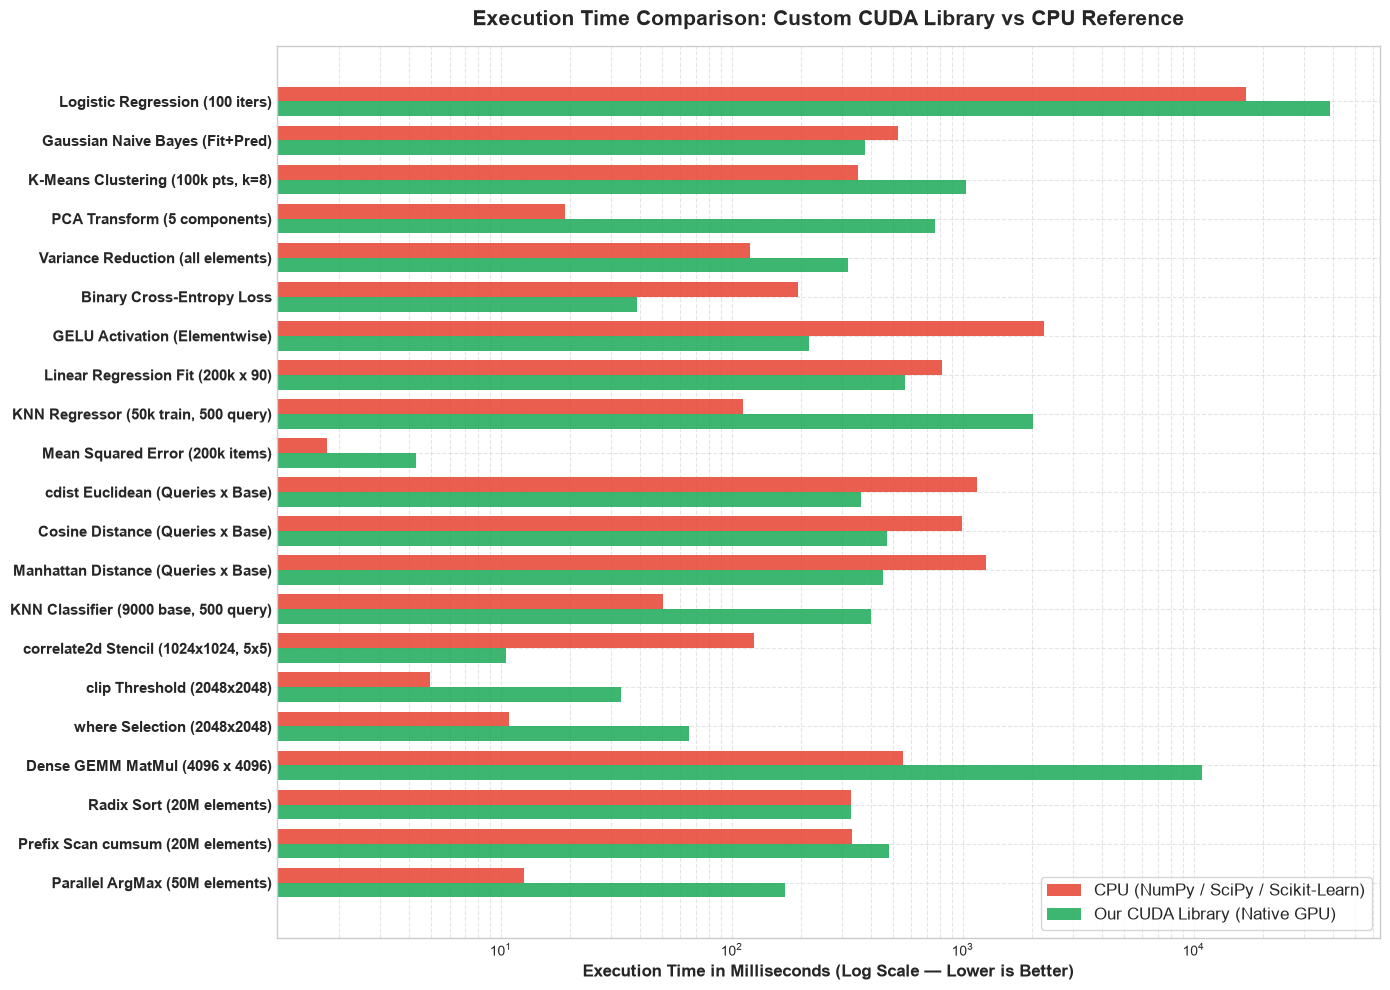

In [13]:
# -------------------------------------------------------------------------
# Figure 1: Side-by-Side Execution Times (Log Scale)
# -------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(14, 10))

y_indices = np.arange(len(df_results))
bar_height = 0.38

bars_cpu = ax.barh(y_indices - bar_height/2, df_results["CPU Time (ms)"], bar_height, 
                   label="CPU (NumPy / SciPy / Scikit-Learn)", color="#e74c3c", alpha=0.9)
bars_cuda = ax.barh(y_indices + bar_height/2, df_results["CUDA Time (ms)"], bar_height, 
                    label="Our CUDA Library (Native GPU)", color="#27ae60", alpha=0.9)

ax.set_yticks(y_indices)
ax.set_yticklabels(df_results["Benchmark"], fontsize=11, fontweight="bold")
ax.set_xscale("log")
ax.set_xlabel("Execution Time in Milliseconds (Log Scale — Lower is Better)", fontsize=12, fontweight="bold")
ax.set_title("Execution Time Comparison: Custom CUDA Library vs CPU Reference", fontsize=15, fontweight="bold", pad=15)
ax.legend(loc="lower right", fontsize=12, frameon=True)
ax.grid(True, which="both", ls="--", alpha=0.5)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

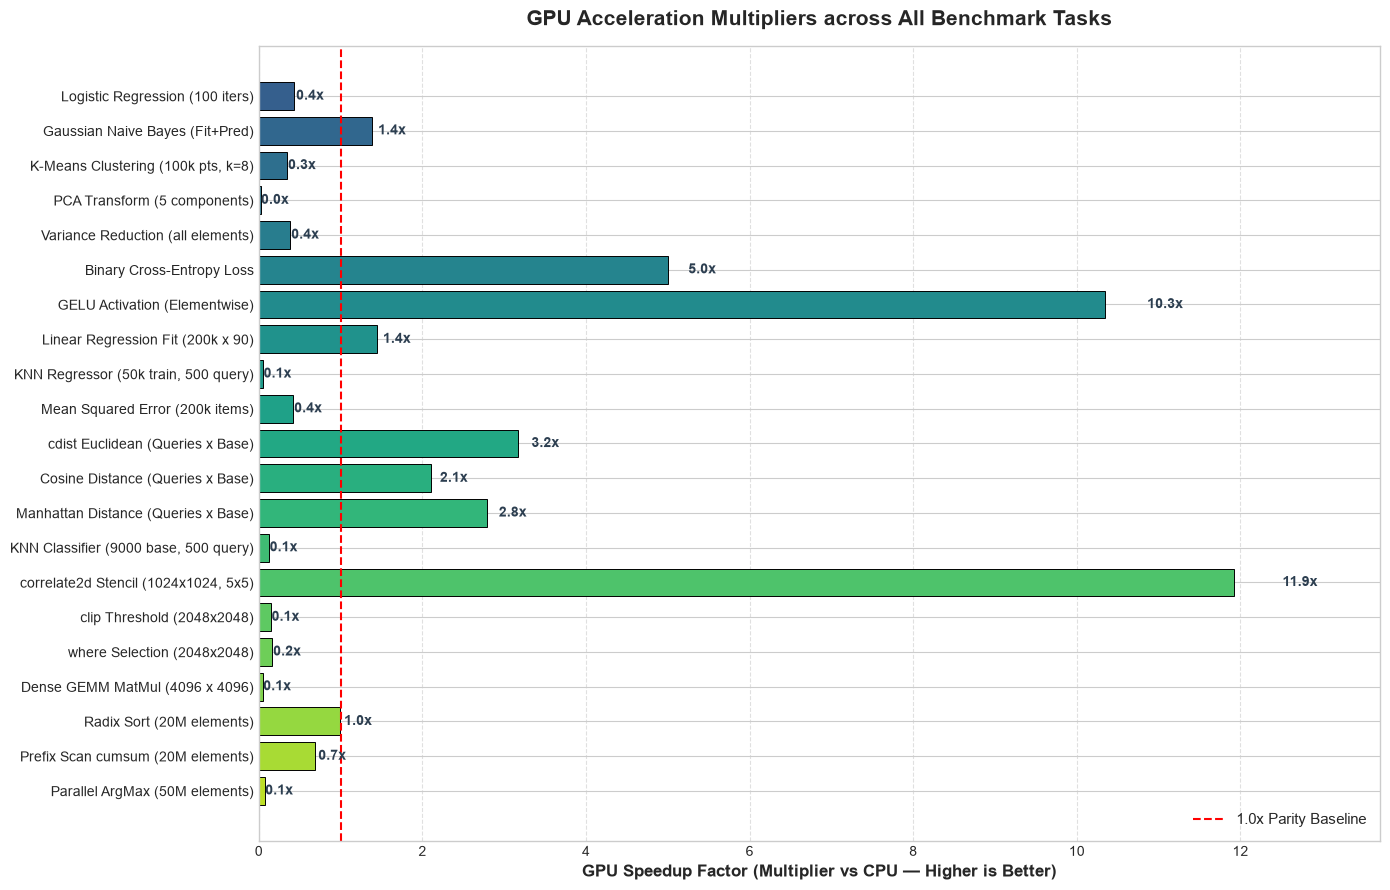

In [14]:
# -------------------------------------------------------------------------
# Figure 2: Speedup Acceleration Factor (CUDA vs CPU)
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 9))

norm_speedups = df_results["Speedup"].values
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(df_results)))

bars = ax.barh(df_results["Benchmark"], norm_speedups, color=colors, edgecolor="black", linewidth=0.7)

# Annotate exact speedup values on each bar
for bar in bars:
    width = bar.get_width()
    ax.text(width * 1.05, bar.get_y() + bar.get_height()/2.0, 
            f"{width:0.1f}x", 
            va="center", ha="left", fontsize=10, fontweight="bold", color="#2c3e50")

ax.set_xlabel("GPU Speedup Factor (Multiplier vs CPU — Higher is Better)", fontsize=12, fontweight="bold")
ax.set_title("GPU Acceleration Multipliers across All Benchmark Tasks", fontsize=15, fontweight="bold", pad=15)
ax.axvline(1.0, color="red", linestyle="--", linewidth=1.5, label="1.0x Parity Baseline")
ax.set_xlim(0, max(norm_speedups) * 1.15)
ax.legend(loc="lower right", fontsize=11)
ax.grid(True, axis="x", ls="--", alpha=0.6)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

---
## 7. Ray Tracer Benchmark & Visual Rendering
Finally, we benchmark the **3D Ray Tracer**:
1. **Python CPU Ray Tracer** (a faithful port of `Ray-Tracer.py`, including shadows)
2. **Parallel CUDA Ray Tracer** (`raytracer_cuda.render_scene`)

Both render the same scene (reflective spheres, glossy materials, ambient & specular lighting, checkerboard floor) at a small comparison resolution, because the pure-Python tracer is extremely slow. The CUDA tracer is also rendered at full 720x480, and the images are shown side by side.


In [15]:
# Scene configuration for Ray Tracing Benchmark
# The pure-Python CPU tracer is ~10^4-10^5x slower than the GPU, so BOTH are timed at a
# small comparison resolution. The CUDA tracer is additionally rendered at full 720x480.
w_cmp, h_cmp = 240, 160          # same 3:2 aspect as 720x480 -> identical screen rectangle S
w_render, h_render = 720, 480    # high-res CUDA-only showcase
r_aspect = float(w_render) / h_render
S_screen = (-1.0, -1.0 / r_aspect + 0.25, 1.0, 1.0 / r_aspect + 0.25)

O_cam = [0.0, 0.35, -1.0]
L_light = [-4.0, 5.0, -10.0]
color_light = [1.0, 1.0, 1.0]
ambient = 0.05
specular_k = 50.0
depth_max = 5

spheres_cfg = [
    {"position": [0.75, 0.1, 1.0], "radius": 0.6, "color": [0.0, 0.0, 1.0], "reflection": 0.5, "diffuse_c": 1.0, "specular_c": 1.0},
    {"position": [-0.75, 0.1, 2.25], "radius": 0.6, "color": [0.5, 0.223, 0.5], "reflection": 0.5, "diffuse_c": 1.0, "specular_c": 1.0},
    {"position": [-2.75, 0.1, 3.5], "radius": 0.6, "color": [1.0, 0.572, 0.184], "reflection": 0.5, "diffuse_c": 1.0, "specular_c": 1.0},
]
planes_cfg = [
    {"position": [0.0, -0.5, 0.0], "normal": [0.0, 1.0, 0.0], "color0": [1.0, 1.0, 1.0], "color1": [0.0, 0.0, 0.0], "reflection": 0.25, "diffuse_c": 0.75, "specular_c": 0.5}
]

print(f"Comparison render: {w_cmp} x {h_cmp} ({w_cmp * h_cmp:,} px)  |  CUDA showcase: {w_render} x {h_render} ({w_render * h_render:,} px)")


Comparison render: 240 x 160 (38,400 px)  |  CUDA showcase: 720 x 480 (345,600 px)


In [16]:
# CPU Ray Tracer - faithful port of Ray-Tracer.py (same algorithm the CUDA kernel implements).
# FIXES vs. the original notebook version:
#   * added the SHADOW test (Ray-Tracer.py / CUDA kernel stop tracing when a point is shadowed;
#     the notebook version had none, so the two images differed),
#   * checkerboard now uses int(M*2) % 2 truncation exactly like Ray-Tracer.py and
#     Plane::get_color (the notebook used floor() parity, which gives a different pattern),
#   * diffuse term no longer multiplied by the light colour (Ray-Tracer.py only applies it to the specular term),
#   * float64 maths like the reference script.
def render_cpu(w, h, S, O, L, color_light, ambient, specular_k, depth_max, spheres, planes):
    def norm(x): return x / np.linalg.norm(x)

    def intersect_sphere(O, D, C, R):
        a = np.dot(D, D)
        OS = O - C
        b = 2 * np.dot(D, OS)
        c = np.dot(OS, OS) - R * R
        disc = b * b - 4 * a * c
        if disc > 0:
            sq = np.sqrt(disc)
            q = (-b - sq) / 2.0 if b < 0 else (-b + sq) / 2.0
            t0, t1 = q / a, c / q
            t0, t1 = min(t0, t1), max(t0, t1)
            if t1 >= 0:
                return t1 if t0 < 0 else t0
        return np.inf

    def intersect_plane(O, D, P, N):
        denom = np.dot(D, N)
        if np.abs(denom) < 1e-6:
            return np.inf
        d = np.dot(P - O, N) / denom
        return d if d >= 0 else np.inf

    # Pre-convert scene to float64 arrays once
    objs = []
    for s in spheres:
        objs.append(dict(kind="sphere", pos=np.array(s["position"], float), radius=float(s["radius"]),
                         color=np.array(s["color"], float), refl=s["reflection"],
                         diff=s["diffuse_c"], spec=s["specular_c"]))
    for p in planes:
        objs.append(dict(kind="plane", pos=np.array(p["position"], float), normal=np.array(p["normal"], float),
                         c0=np.array(p["color0"], float), c1=np.array(p["color1"], float),
                         refl=p["reflection"], diff=p["diffuse_c"], spec=p["specular_c"]))

    def intersect(O, D, o):
        return (intersect_sphere(O, D, o["pos"], o["radius"]) if o["kind"] == "sphere"
                else intersect_plane(O, D, o["pos"], o["normal"]))

    O_arr = np.array(O, float); L_arr = np.array(L, float); col_light = np.array(color_light, float)
    img = np.zeros((h, w, 3), dtype=np.float32)
    xs = np.linspace(S[0], S[2], w)
    ys = np.linspace(S[1], S[3], h)

    for i, x in enumerate(xs):
        for j, y in enumerate(ys):
            D = norm(np.array([x, y, 0.0]) - O_arr)
            rayO, rayD = O_arr.copy(), D
            col = np.zeros(3)
            refl = 1.0
            for _ in range(depth_max):
                t_min, idx = np.inf, -1
                for k, o in enumerate(objs):
                    t = intersect(rayO, rayD, o)
                    if t < t_min:
                        t_min, idx = t, k
                if idx < 0:
                    break
                o = objs[idx]
                M = rayO + rayD * t_min
                if o["kind"] == "sphere":
                    N = norm(M - o["pos"]); base = o["color"]
                else:
                    N = o["normal"]
                    base = o["c0"] if (int(M[0] * 2) % 2) == (int(M[2] * 2) % 2) else o["c1"]
                toL = norm(L_arr - M)
                toO = norm(O_arr - M)
                # Shadow test against every OTHER object -> terminates the ray (as in Ray-Tracer.py)
                sh_O = M + N * 1e-4
                if any(intersect(sh_O, toL, other) < np.inf for k, other in enumerate(objs) if k != idx):
                    break
                col_ray = ambient + o["diff"] * max(np.dot(N, toL), 0.0) * base
                col_ray = col_ray + o["spec"] * max(np.dot(N, norm(toL + toO)), 0.0) ** specular_k * col_light
                col += refl * col_ray
                refl *= o["refl"]
                rayO = M + N * 1e-4
                rayD = norm(rayD - 2.0 * np.dot(rayD, N) * N)
            img[h - j - 1, i, :] = np.clip(col, 0.0, 1.0)
    return img

print("CPU Ray Tracer ready.")


CPU Ray Tracer ready.


In [17]:
# Measure Execution Time: CUDA vs CPU at the SAME resolution
def cuda_render(w, h):
    return raytracer_cuda.render_scene(
        w, h, depth_max, ambient, specular_k,
        O_cam, L_light, color_light, list(S_screen),
        spheres_cfg, planes_cfg
    )

_ = cuda_render(w_cmp, h_cmp)            # warm-up: CUDA context init must not be counted

print(f"Starting CUDA Ray Tracer ({w_cmp}x{h_cmp})...")
t0 = time.perf_counter()
img_cuda = cuda_render(w_cmp, h_cmp)
t_cuda_rt = time.perf_counter() - t0
print(f"CUDA Ray Tracer Completed in: {t_cuda_rt:.4f} seconds")

print(f"Starting CPU Ray Tracer ({w_cmp}x{h_cmp}) - pure Python, this takes a while...")
t0 = time.perf_counter()
img_cpu = render_cpu(
    w_cmp, h_cmp, S_screen, O_cam, L_light, color_light,
    ambient, specular_k, depth_max, spheres_cfg, planes_cfg
)
t_cpu_rt = time.perf_counter() - t0
print(f"CPU Ray Tracer Completed in:  {t_cpu_rt:.4f} seconds")

speedup_rt = t_cpu_rt / t_cuda_rt if t_cuda_rt > 0 else float("nan")
print(f"\n>>> Ray Tracer Acceleration: {speedup_rt:.1f}x Faster on GPU <<<")

# Correctness: both images should agree up to float32-vs-float64 rounding at a few edge pixels
diff = np.abs(img_cuda.astype(np.float32) - img_cpu)
print(f"Image agreement: mean |diff| = {diff.mean():.5f}, pixels differing by >0.05: {(diff.max(axis=2) > 0.05).mean()*100:.3f}%")

# CUDA-only high-resolution showcase
t0 = time.perf_counter()
img_cuda_hi = cuda_render(w_render, h_render)
t_cuda_hi = time.perf_counter() - t0
print(f"CUDA {w_render}x{h_render} render: {t_cuda_hi*1000:.2f} ms ({w_render*h_render/t_cuda_hi/1e6:.1f} Mpixels/s)")


Starting CUDA Ray Tracer (240x160)...
CUDA Ray Tracer Completed in: 0.0033 seconds
Starting CPU Ray Tracer (240x160) - pure Python, this takes a while...
CPU Ray Tracer Completed in:  7.6868 seconds

>>> Ray Tracer Acceleration: 2333.4x Faster on GPU <<<
Image agreement: mean |diff| = 0.00003, pixels differing by >0.05: 0.000%
CUDA 720x480 render: 9.19 ms (37.6 Mpixels/s)


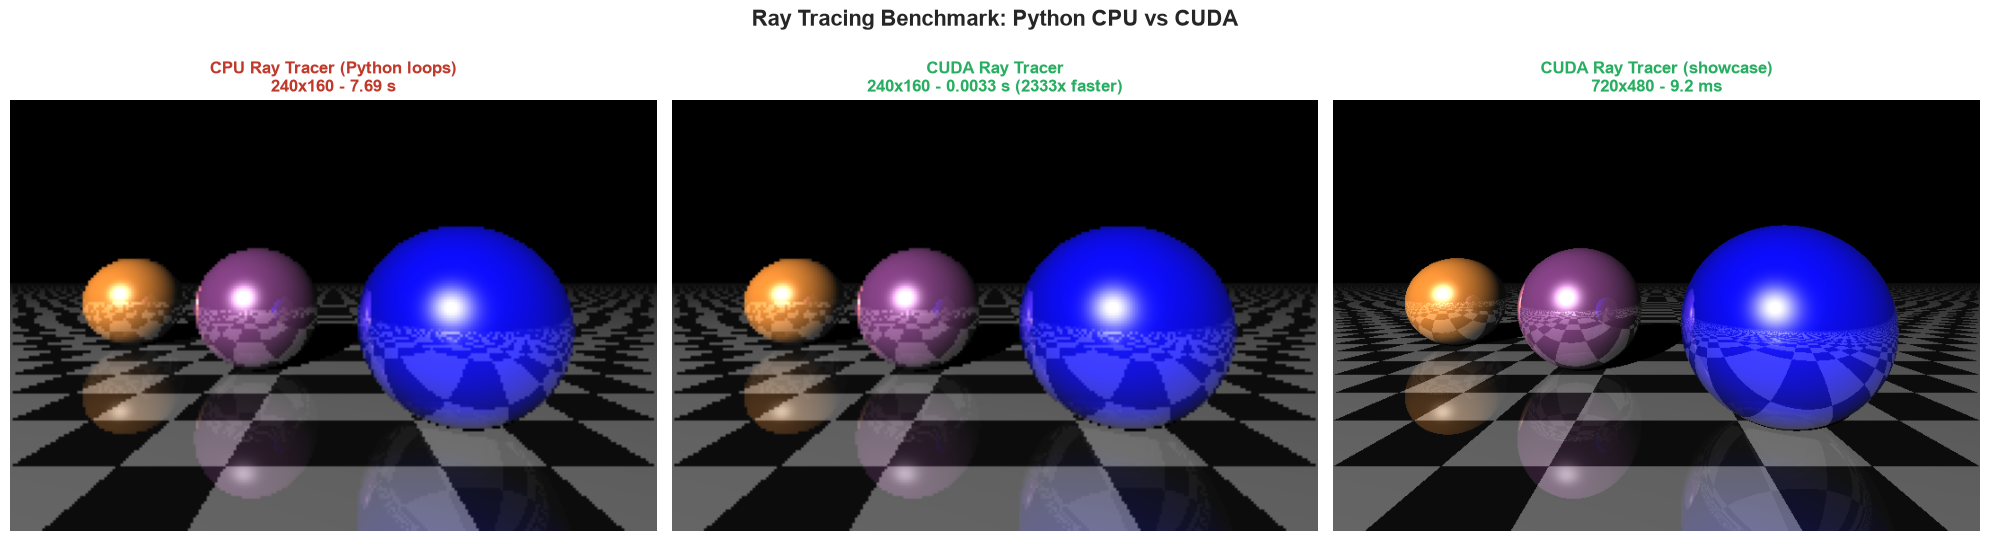

In [18]:
# Visual Output Comparison using Matplotlib
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].imshow(img_cpu)
axes[0].set_title(f"CPU Ray Tracer (Python loops)\n{w_cmp}x{h_cmp} - {t_cpu_rt:.2f} s", fontsize=12, fontweight="bold", color="#c0392b")
axes[0].axis("off")

axes[1].imshow(img_cuda)
axes[1].set_title(f"CUDA Ray Tracer\n{w_cmp}x{h_cmp} - {t_cuda_rt:.4f} s ({speedup_rt:.0f}x faster)", fontsize=12, fontweight="bold", color="#27ae60")
axes[1].axis("off")

axes[2].imshow(img_cuda_hi)
axes[2].set_title(f"CUDA Ray Tracer (showcase)\n{w_render}x{h_render} - {t_cuda_hi*1000:.1f} ms", fontsize=12, fontweight="bold", color="#27ae60")
axes[2].axis("off")

plt.suptitle("Ray Tracing Benchmark: Python CPU vs CUDA", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()
